## Dataset:https://www.kaggle.com/datasets/gun0207/dirty-cafe-sales-cleaned

My tasks:

1)Exploratory Data Analysis

2)Data Cleaning

3)Prepare for creating Power BI dashboard

In [ ]:
import pandas as pd

In [ ]:
import seaborn as sns

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
import numpy as np

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:


file_path = "/content/drive/MyDrive/CSV_files_for_DATA_cleaning/cafe_sales_cleaned_checkpoint.csv"

df_clean = pd.read_csv(
    file_path,
    parse_dates=["transaction_date"]
)

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  object        
 1   item              9031 non-null   object        
 2   quantity          9977 non-null   float64       
 3   price_per_unit    9994 non-null   float64       
 4   total_spent       9498 non-null   float64       
 5   payment_method    6822 non-null   object        
 6   location          6039 non-null   object        
 7   transaction_date  9540 non-null   datetime64[ns]
 8   total_spent_calc  9006 non-null   float64       
dtypes: datetime64[ns](1), float64(4), object(4)
memory usage: 703.3+ KB


In [ ]:
df_clean.isna().sum()

,0
transaction_id,0
item,969
quantity,23
price_per_unit,6
total_spent,502
payment_method,3178
location,3961
transaction_date,460
total_spent_calc,994


In [ ]:
df_clean['transaction_date'].dtype

dtype('<M8[ns]')

In [ ]:
#зробимо копію

In [ ]:
df_eda = df_clean.copy()

In [ ]:
#EDA
# 1) general info

In [ ]:
print('К-сть рядків:', df_eda.shape[0])
print('К-сть стовпців:', df_eda.shape[1])

К-сть рядків: 10000
К-сть стовпців: 9


In [ ]:
df_eda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    10000 non-null  object        
 1   item              9031 non-null   object        
 2   quantity          9977 non-null   float64       
 3   price_per_unit    9994 non-null   float64       
 4   total_spent       9498 non-null   float64       
 5   payment_method    6822 non-null   object        
 6   location          6039 non-null   object        
 7   transaction_date  9540 non-null   datetime64[ns]
 8   total_spent_calc  9006 non-null   float64       
dtypes: datetime64[ns](1), float64(4), object(4)
memory usage: 703.3+ KB


In [ ]:
#check for duplicates

In [ ]:
df_eda.duplicated().sum()

np.int64(0)

In [ ]:
#check for duplicated id

In [ ]:
df_eda['transaction_id'].duplicated().sum()

np.int64(0)

In [ ]:
# stat of numeric columns

In [ ]:
df_eda[
    ["quantity", "price_per_unit", "total_spent"]
].describe()

,quantity,price_per_unit,total_spent
count,9977.000000,9994.000000,9498.000000
mean,3.024957,2.947018,8.924352
std,1.420395,1.280006,6.009919
min,1.000000,1.000000,1.000000
25%,2.000000,2.000000,4.000000
50%,3.000000,3.000000,8.000000
75%,4.000000,4.000000,12.000000
max,5.000000,5.000000,25.000000


In [ ]:
print("Розмір:", df_eda.shape)

df_eda[
    ["quantity", "price_per_unit", "total_spent"]
].isna().sum()

Розмір: (10000, 9)


,0
quantity,23
price_per_unit,6
total_spent,502


In [ ]:
!find /content/drive/MyDrive -iname "*cafe*.csv"

/content/drive/MyDrive/CSV_files _for_DATA_cleaning/dirty_cafe_sales.csv
/content/drive/MyDrive/CSV_files_for_DATA_cleaning/cafe_sales_cleaned_checkpoint.csv
/content/drive/MyDrive/CSV_files_for_DATA_cleaning/cafe_sales_cleaned.csv


In [ ]:
#Check distribution of quantity

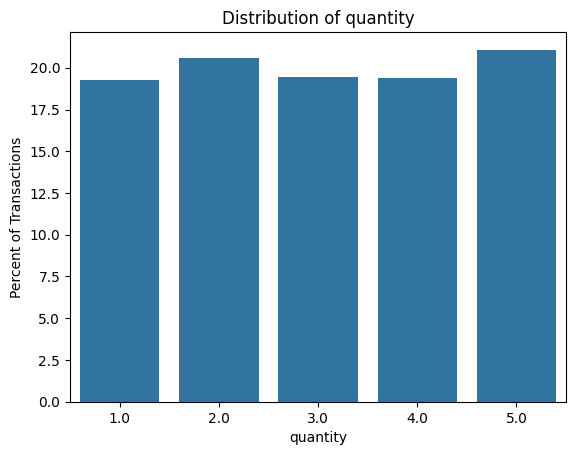

In [ ]:
sns.countplot(
    data=df_eda, x='quantity', stat='percent'
)
plt.title("Distribution of quantity")
plt.ylabel('Percent of Transactions')
plt.show()

In [ ]:
df_eda['quantity'].value_counts(
    dropna=False
).sort_index()

,count
quantity,
1.0,1926
2.0,2056
3.0,1946
4.0,1941
5.0,2108
NaN,23


[Text(0, 0, '19.3'),
 Text(0, 0, '20.6'),
 Text(0, 0, '19.5'),
 Text(0, 0, '19.4'),
 Text(0, 0, '21.1')]

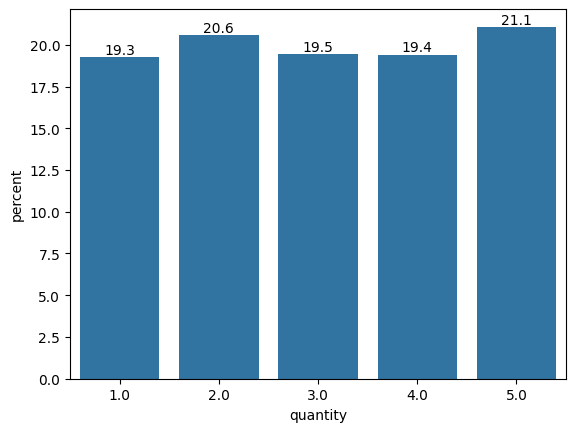

In [ ]:
ax = sns.countplot(
    data=df_clean,
    x="quantity",
    stat="percent"
)

ax.bar_label(ax.containers[0], fmt="%.1f")

In [ ]:
# price per unit

[Text(0, 0, '12.1'),
 Text(0, 0, '12.1'),
 Text(0, 0, '12.9'),
 Text(0, 0, '25.6'),
 Text(0, 0, '24.5'),
 Text(0, 0, '12.7')]

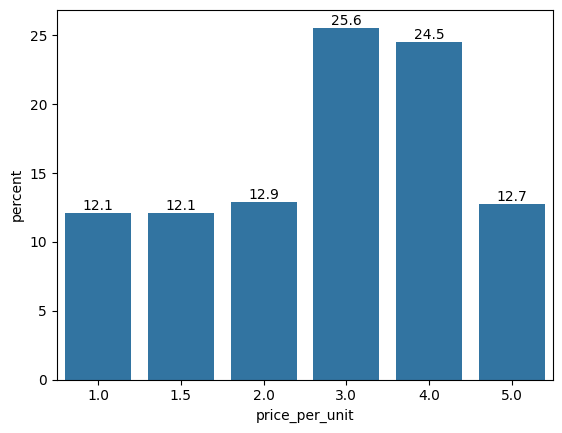

In [ ]:
ax = sns.countplot(
    data=df_clean,
    x="price_per_unit",
    stat="percent"
)

ax.bar_label(ax.containers[0], fmt="%.1f")

[Text(0, 0, '1213'),
 Text(0, 0, '1207'),
 Text(0, 0, '1291'),
 Text(0, 0, '2557'),
 Text(0, 0, '2454'),
 Text(0, 0, '1272')]

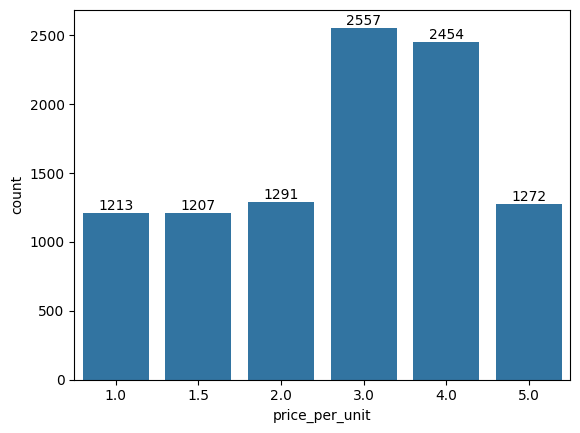

In [ ]:
ax = sns.countplot(
    data=df_clean,
    x="price_per_unit"

)
ax.bar_label(ax.containers[0])

In [ ]:
df_clean['price_per_unit'].mean()

np.float64(2.947018210926556)

In [ ]:
df_clean['price_per_unit'].median()

3.0

In [ ]:
# total spent

Text(0, 0.5, 'Number of transactions')

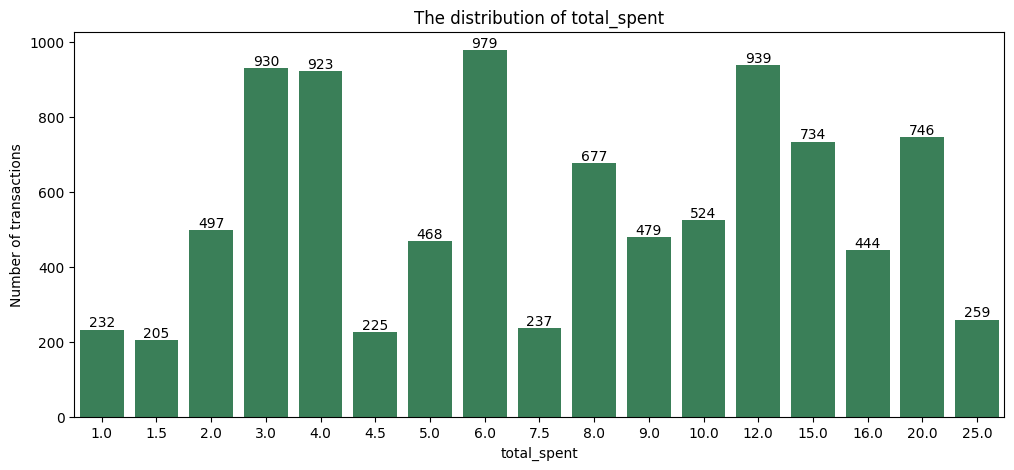

In [ ]:
plt.figure(figsize=(12, 5))

ax = sns.countplot(
    data=df_clean,
    x="total_spent",
    color="seagreen"

)
ax.bar_label(ax.containers[0])
plt.title("The distribution of total_spent")
plt.ylabel("Number of transactions")

In [ ]:
# mean and mediana of 'total_spent'

In [ ]:
print("The mean total of all orders:",df_eda['total_spent'].mean())

The mean total of all orders: 8.924352495262161


In [ ]:
print("The mdeian total of all orders:",df_eda['total_spent'].median())

The mdeian total of all orders: 8.0


In [ ]:
#переходимо до самих items

In [ ]:
#вивести графік який демонструє які товари замовляють найчастіше

[Text(0, 0, '1165'),
 Text(0, 0, '1139'),
 Text(0, 0, '1092'),
 Text(0, 0, '1148'),
 Text(0, 0, '1096'),
 Text(0, 0, '1131'),
 Text(0, 0, '1171'),
 Text(0, 0, '1089')]

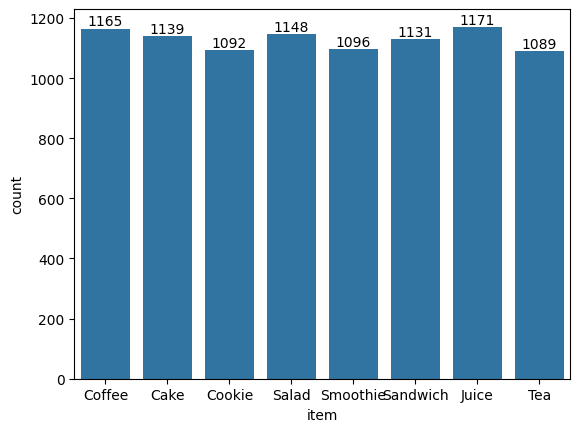

In [ ]:
ax = sns.countplot(
    data=df_eda, x='item'
)
ax.bar_label(ax.containers[0])

In [ ]:
ax.containers[0]

<BarContainer object of 8 artists>

In [ ]:
df_eda.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,total_spent_calc
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,4.0
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,12.0
2,TXN_4271903,Cookie,4.0,1.0,NaN,Credit Card,In-store,2023-07-19,4.0
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27,10.0
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,4.0


In [ ]:
#Який товар приносить найбільше доходу

In [ ]:
df_eda['item'].value_counts()

,count
item,
Juice,1171
Coffee,1165
Salad,1148
Cake,1139
Sandwich,1131
Smoothie,1096
Cookie,1092
Tea,1089


In [ ]:
price_list = (
    df_eda[['item','price_per_unit']].value_counts().reset_index(name='count')
);

In [ ]:
price_list

,item,price_per_unit,count
0,Juice,3.0,1171
1,Coffee,2.0,1165
2,Salad,5.0,1148
3,Cake,3.0,1139
4,Sandwich,4.0,1131
5,Smoothie,4.0,1096
6,Cookie,1.0,1092
7,Tea,1.5,1089


In [ ]:
price_list['profit'] = price_list['price_per_unit']*price_list['count']

In [ ]:
price_list = (
    df_eda[['item','price_per_unit']].value_counts().reset_index(name='count')
);

In [ ]:
df_eda[['item','total_spent']]

,item,total_spent
0,Coffee,4.0
1,Cake,12.0
2,Cookie,NaN
3,Salad,10.0
4,Coffee,4.0
...,...,...
9995,Coffee,4.0
9996,NaN,3.0
9997,Coffee,8.0
9998,Cookie,3.0


In [ ]:
# ств підсумкову таблицю із товарами

In [ ]:
item_summary = (
    df_clean
    .groupby("item")
    .agg(
        transactions=("transaction_id","count"),
        quantity_sold=("quantity", "sum"),
        revenue=("total_spent", "sum")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

In [ ]:
item_summary

,item,transactions,quantity_sold,revenue
4,Salad,1148,3469.0,16605.0
5,Sandwich,1131,3429.0,12956.0
6,Smoothie,1096,3336.0,12556.0
3,Juice,1171,3505.0,9984.0
0,Cake,1139,3468.0,9933.0
1,Coffee,1165,3536.0,6784.0
7,Tea,1089,3307.0,4735.5
2,Cookie,1092,3232.0,3070.0


In [ ]:
item_summary['average_price'] = (
    item_summary['revenue']/item_summary['quantity_sold']
)
item_summary

,item,transactions,quantity_sold,revenue,average_price
4,Salad,1148,3469.0,16605.0,4.786682
5,Sandwich,1131,3429.0,12956.0,3.778361
6,Smoothie,1096,3336.0,12556.0,3.763789
3,Juice,1171,3505.0,9984.0,2.848502
0,Cake,1139,3468.0,9933.0,2.864187
1,Coffee,1165,3536.0,6784.0,1.918552
7,Tea,1089,3307.0,4735.5,1.431963
2,Cookie,1092,3232.0,3070.0,0.949876


In [ ]:
#побудуємо графіки

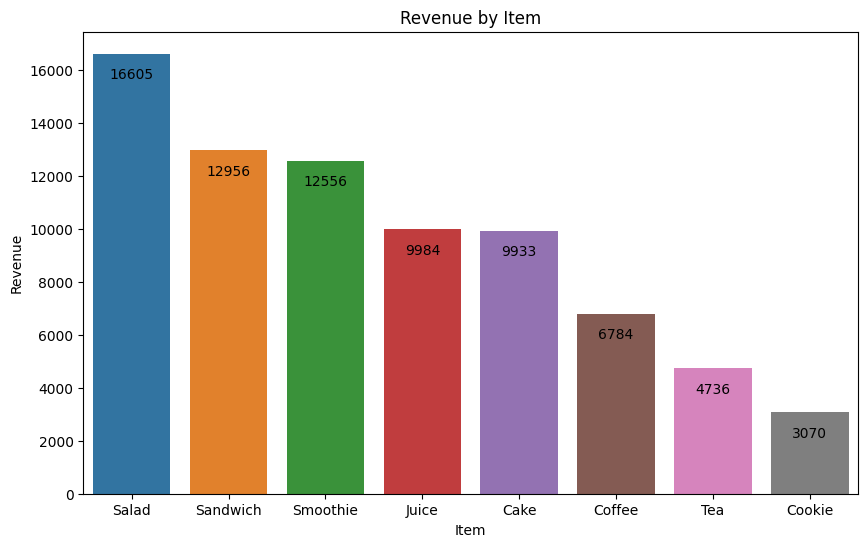

In [ ]:
plt.figure(figsize=(10,6))
ax = sns.barplot(
    data=item_summary,
    x="item",
    y='revenue',
    hue='item'
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=-20
    )

plt.title("Revenue by Item")
plt.xlabel("Item")
plt.ylabel("Revenue")
plt.show()

In [ ]:
item_summary['revenue_percent']=(
    (item_summary['revenue'] / item_summary['revenue'].sum())*100
)

In [ ]:
item_summary.sort_values(by="quantity_sold", ascending=False)

,item,transactions,quantity_sold,revenue,average_price,revenue_percent
1,Coffee,1165,3536.0,6784.0,1.918552,8.853681
3,Juice,1171,3505.0,9984.0,2.848502,13.029945
4,Salad,1148,3469.0,16605.0,4.786682,21.670897
0,Cake,1139,3468.0,9933.0,2.864187,12.963386
5,Sandwich,1131,3429.0,12956.0,3.778361,16.908651
6,Smoothie,1096,3336.0,12556.0,3.763789,16.386618
7,Tea,1089,3307.0,4735.5,1.431963,6.180219
2,Cookie,1092,3232.0,3070.0,0.949876,4.006604


In [ ]:
item_summary.sort_values(by="revenue", ascending=False)

,item,transactions,quantity_sold,revenue,average_price,revenue_percent
4,Salad,1148,3469.0,16605.0,4.786682,21.670897
5,Sandwich,1131,3429.0,12956.0,3.778361,16.908651
6,Smoothie,1096,3336.0,12556.0,3.763789,16.386618
3,Juice,1171,3505.0,9984.0,2.848502,13.029945
0,Cake,1139,3468.0,9933.0,2.864187,12.963386
1,Coffee,1165,3536.0,6784.0,1.918552,8.853681
7,Tea,1089,3307.0,4735.5,1.431963,6.180219
2,Cookie,1092,3232.0,3070.0,0.949876,4.006604


In [ ]:
item_summary['ratio_revenue_to_quantity'] = item_summary["revenue"] / item_summary["quantity_sold"]

In [ ]:
item_summary

,item,transactions,quantity_sold,revenue,average_price,revenue_percent,ratio_revenue_to_quantity
4,Salad,1148,3469.0,16605.0,4.786682,21.670897,4.786682
5,Sandwich,1131,3429.0,12956.0,3.778361,16.908651,3.778361
6,Smoothie,1096,3336.0,12556.0,3.763789,16.386618,3.763789
3,Juice,1171,3505.0,9984.0,2.848502,13.029945,2.848502
0,Cake,1139,3468.0,9933.0,2.864187,12.963386,2.864187
1,Coffee,1165,3536.0,6784.0,1.918552,8.853681,1.918552
7,Tea,1089,3307.0,4735.5,1.431963,6.180219,1.431963
2,Cookie,1092,3232.0,3070.0,0.949876,4.006604,0.949876


In [ ]:
#чекнемо транзакції з пропущеним назвою айтема але порахованим total_spent

In [ ]:
unknown_item_revenue = df_clean.loc[
    df_clean['item'].isna(),
    "total_spent"
].sum()

In [ ]:
unknown_item_revenue

np.float64(8140.0)

In [ ]:
unknown_item_revenue_percent = (
    unknown_item_revenue / df_clean['total_spent'].sum()
)*100

In [ ]:
unknown_item_revenue_percent

np.float64(9.603190052322049)

In [ ]:
unknown_item_revenue, unknown_item_revenue_percent

(np.float64(8140.0), np.float64(9.603190052322049))

In [ ]:
df_clean.loc[
    df_clean['price_per_unit'].isna(),
    ['item','price_per_unit']
]

,item,price_per_unit
1761,NaN,NaN
2289,NaN,NaN
3779,NaN,NaN
4152,NaN,NaN
7597,NaN,NaN
9819,NaN,NaN


In [ ]:
df_clean.loc[
    (df_clean['item'].isna()),
    ['item','price_per_unit']
]

,item,price_per_unit
6,NaN,3.0
8,NaN,3.0
14,NaN,1.5
30,NaN,2.0
31,NaN,1.0
...,...,...
9951,NaN,1.0
9958,NaN,5.0
9981,NaN,4.0
9994,NaN,4.0


In [ ]:
#

In [ ]:
price_item_options = (
    df_clean
    .dropna(subset=["item", "price_per_unit"])
    .groupby("price_per_unit")["item"]
    .agg(lambda items: sorted(items.unique()))
    .reset_index(name="possible_items")
)

price_item_options

,price_per_unit,possible_items
0,1.0,[Cookie]
1,1.5,[Tea]
2,2.0,[Coffee]
3,3.0,"[Cake, Juice]"
4,4.0,"[Sandwich, Smoothie]"
5,5.0,[Salad]


In [ ]:
price_to_item ={
    1.0: "Cookie",
    1.5: "Tea",
    2.0: "Coffee",
    5.0: "Salad"
}


In [ ]:
restored_items = df_clean['price_per_unit'].map(price_to_item)

item_restore_mask = (
    df_clean['item'].isna()
    & restored_items.notna()
)

In [ ]:
item_restore_mask.sum()

np.int64(489)

In [ ]:
df_clean.loc[
    item_restore_mask, ['item']
] = (restored_items[item_restore_mask])

In [ ]:
# чек тепер скільки

In [ ]:
df_clean.loc[
    (df_clean['item'].isna()),
    ['item','price_per_unit']
]

,item,price_per_unit
6,NaN,3.0
8,NaN,3.0
36,NaN,3.0
61,NaN,3.0
69,NaN,3.0
...,...,...
9910,NaN,3.0
9918,NaN,4.0
9946,NaN,4.0
9981,NaN,4.0


In [ ]:
df_clean['item'].isna().sum()

np.int64(480)

In [ ]:
df_clean["item"].value_counts(dropna=False)

,count
item,
Coffee,1291
Salad,1272
Cookie,1213
Tea,1207
Juice,1171
Cake,1139
Sandwich,1131
Smoothie,1096
NaN,480


In [ ]:
mask = df_clean['item'].notna() & df_clean['price_per_unit'].isna()

In [ ]:
mask.sum()

np.int64(0)

In [ ]:
#повторно аналіз товарів

In [ ]:
item_summary = (
    df_clean
    .assign(item=df_clean['item'].fillna("Unknown"))
    .groupby("item")
    .agg(transactions = ("transaction_id", "count"),
         quantity_sold = ("quantity", "sum"),
         revenue = ("total_spent", sum)

    ).reset_index()
)

/tmp/ipykernel_1316/3601323962.py:5: FutureWarning: The provided callable <built-in function sum> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  .agg(transactions = ("transaction_id", "count"),


In [ ]:
item_summary

,item,transactions,quantity_sold,revenue
0,Cake,1139,3468.0,9933.0
1,Coffee,1291,3904.0,7482.0
2,Cookie,1213,3598.0,3417.0
3,Juice,1171,3505.0,9984.0
4,Salad,1272,3819.0,18295.0
5,Sandwich,1131,3429.0,12956.0
6,Smoothie,1096,3336.0,12556.0
7,Tea,1207,3650.0,5227.5
8,Unknown,480,1471.0,4913.0


In [ ]:
item_summary["average_price"] = (
    item_summary["revenue"]
    / item_summary["quantity_sold"]
)

item_summary["revenue_percent"] = (
    item_summary["revenue"]
    / item_summary["revenue"].sum()
    * 100
)

In [ ]:
item_summary = item_summary.sort_values(
    "revenue",
    ascending=False
).reset_index(drop=True)

In [ ]:
item_summary.style.format({
    "revenue": "{:.2f}",
    "average_price": "{:.2f}",
    "revenue_percent": "{:.2f}%"
})

,item,transactions,quantity_sold,revenue,average_price,revenue_percent
0,Salad,1272,3819.000000,18295.00,4.79,21.58%
1,Sandwich,1131,3429.000000,12956.00,3.78,15.28%
2,Smoothie,1096,3336.000000,12556.00,3.76,14.81%
3,Juice,1171,3505.000000,9984.00,2.85,11.78%
4,Cake,1139,3468.000000,9933.00,2.86,11.72%
5,Coffee,1291,3904.000000,7482.00,1.92,8.83%
6,Tea,1207,3650.000000,5227.50,1.43,6.17%
7,Unknown,480,1471.000000,4913.00,3.34,5.80%
8,Cookie,1213,3598.000000,3417.00,0.95,4.03%


In [ ]:
#Графік к-сті проданих одиниць за кожним товаром

In [ ]:
plt.figure(figsize=(10,6))
ax =  sns.barplot(
    data = item_summary,
    x = "item",
    y="quantity_sold",
    hue="item",
    order = quantity_order_by_item
)

for i in range(len(ax.containers)):
  ax.bar_label(ax.containers[i])
plt.tight_layout()


NameError: name 'quantity_order_by_item' is not defined

<Figure size 1000x600 with 0 Axes>

In [ ]:
# для параметра order


In [ ]:
quantity_order_by_item = (
    item_summary
    .sort_values(by='quantity_sold', ascending = False)["item"]
)

In [ ]:
quantity_order_by_item

In [ ]:
revenue_order_by_item = (
    item_summary
    .sort_values(by='revenue', ascending = False)["item"]
)

In [ ]:
plt.figure(figsize=(10,6))
ax =  sns.barplot(
    data = item_summary,
    x = "item",
    y="revenue",
    hue="item",
    order = revenue_order_by_item
)

for i in range(len(ax.containers)):
  ax.bar_label(ax.containers[i])
plt.tight_layout()

In [ ]:
plt.figure(figsize=(10,6))
ax =  sns.barplot(
    data = item_summary,
    x = "item",
    y="quantity_sold",
    hue="item",
    order = quantity_order_by_item
)

for i in range(len(ax.containers)):
  ax.bar_label(ax.containers[i])
plt.tight_layout()

In [ ]:
item_summary["revenue_rank"]=(
    item_summary['revenue']
    .rank(method='dense', ascending = False)
).astype(dtype=int)

In [ ]:
item_summary

In [ ]:
item_summary["quantity_rank"] = (
    item_summary["quantity_sold"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

In [ ]:
item_summary

In [ ]:
item_summary["revenue"].sum() / item_summary["quantity_sold"].sum()

In [ ]:
df_clean.loc[
    df_clean['item']=='Salad',
    "price_per_unit"
].value_counts(dropna=False)

In [ ]:
salad_mask = df_clean["item"] == "Salad"

salad_mismatch_mask = (
    salad_mask
    & ~np.isclose(
        df_clean["total_spent"],
        df_clean["quantity"] * df_clean["price_per_unit"]
    )
)

salad_mismatch_mask.sum()

In [ ]:
df_clean[['item','price_per_unit']]

In [ ]:
salad_mask = df_clean["item"] == "Salad"

salad_mismatch_mask = (
    salad_mask
    & ~np.isclose(
        df_clean["total_spent"],
        df_clean["quantity"] * df_clean["price_per_unit"]
    )
)

salad_mismatch_mask.sum()

In [ ]:
#подивимося на ці рядки

In [ ]:
salad_mismatches = df_clean.loc[
    salad_mismatch_mask,[
        "transaction_id",
        "item",
        "quantity",
        "price_per_unit",
        "total_spent"
    ]
].copy()

In [ ]:
salad_mismatches['calculated_total'] = (
    salad_mismatches['quantity']
    *salad_mismatches['price_per_unit'])

In [ ]:
salad_mismatches['difference'] = (
    salad_mismatches['total_spent']-salad_mismatches['calculated_total']
)

In [ ]:
salad_mismatches.head(10)

In [ ]:
salad_mismatches = df_clean.loc[
    salad_mismatch_mask,
    [
        "transaction_id",
        "item",
        "quantity",
        "price_per_unit",
        "total_spent"
    ]
].copy()

salad_mismatches["calculated_total"] = (
    salad_mismatches["quantity"]
    * salad_mismatches["price_per_unit"]
)

salad_mismatches["difference"] = (
    salad_mismatches["total_spent"]
    - salad_mismatches["calculated_total"]
)

salad_mismatches.head(10)

In [ ]:
df_clean[
    ["quantity", "price_per_unit", "total_spent"]
].isna().sum()

In [ ]:
df_clean[df_clean['price_per_unit'].isna()]

In [ ]:
df_clean[
    ["quantity", "price_per_unit", "total_spent"]
].isna().sum()

In [ ]:
#відновимо total_spent там де є і price_per_unit і quantity

In [ ]:
total_restore_mask = (
    df_clean['total_spent'].isna()
    &df_clean['quantity'].notna()
    &df_clean['price_per_unit'].notna()

)
total_restore_mask.sum()

In [ ]:
#заповнюємо

In [ ]:
df_clean.loc[
    total_restore_mask,
    ["total_spent"]
] = (
    df_clean.loc[total_restore_mask,"quantity"] * df_clean.loc[total_restore_mask,"price_per_unit"]
)


In [ ]:
df_clean.isna().sum()

In [ ]:
item_summary["revenue_rank"] = (
    item_summary["revenue"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

item_summary["quantity_rank"] = (
    item_summary["quantity_sold"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

In [ ]:
item_summary

In [ ]:
item_summary = (
    item_summary
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)

In [ ]:
item_summary

In [ ]:
item_summary.style.format({
    "revenue": "{:.2f}",
    "average_price": "{:.2f}",
    "revenue_percent": "{:.2f}%"
})

In [ ]:
item_summary = (
    df_clean
    .assign(item=df_clean["item"].fillna("Unknown"))
    .groupby("item")
    .agg(
        transactions=("transaction_id", "count"),
        quantity_sold=("quantity", "sum"),
        revenue=("total_spent", "sum")
    )
    .reset_index()
)

In [ ]:
item_summary["average_price"] = (
    item_summary["revenue"]
    / item_summary["quantity_sold"]
)

item_summary["revenue_percent"] = (
    item_summary["revenue"]
    / item_summary["revenue"].sum()
    * 100
)

In [ ]:
item_summary["revenue_rank"] = (
    item_summary["revenue"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

item_summary["quantity_rank"] = (
    item_summary["quantity_sold"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

In [ ]:
item_summary = (
    item_summary
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)

In [ ]:
item_summary

In [ ]:
df_clean.to_csv(file_path, index=False)

In [ ]:
##########################
import pandas as pd
import seaborn as sns

In [ ]:
import matplotlib.pyplot as plt


In [ ]:
file_path = "/content/drive/MyDrive/CSV_files_for_DATA_cleaning/data_clean_06_09.csv"

In [ ]:

file_path = "/content/drive/MyDrive/CSV_files_for_DATA_cleaning/data_clean_06_09.csv"

df_clean = pd.read_csv(
    file_path,
    parse_dates=["transaction_date"]
)

In [ ]:
#Оцінюємо payment methods

In [ ]:
df_clean.head()

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,total_spent_calc
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,4.0
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,12.0
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,4.0
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,NaN,2023-04-27,10.0
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,4.0


In [ ]:
plt.figure(figsize=(10,6))
ax = sns.barplot(
    data=df_clean,
    x="payment_method",
    y="transaction_id",
    hue = "payment_method",
    estimator = "sum"
)

for cont in ax.containers:
  ax.bar_label(cont, padding=-50)


Error in callback <function _draw_all_if_interactive at 0x79b8b603f560> (for post_execute):


KeyboardInterrupt: 

Error in callback <function flush_figures at 0x79b8b603c9a0> (for post_execute):


KeyboardInterrupt: 

In [ ]:
payment_method_analysis = (
    df_clean["payment_method"]
    .fillna('Unknown')
    .value_counts()
    .rename_axis("payment_method")
    .reset_index(name="count")

)

In [ ]:
payment_method_analysis

,payment_method,count
0,Unknown,3178
1,Digital Wallet,2291
2,Credit Card,2273
3,Cash,2258


In [ ]:
payment_method_analysis["percentage"] = (
    payment_method_analysis["count"]
    / payment_method_analysis["count"].sum()
    * 100
).round(2)

In [ ]:
payment_method_analysis

In [ ]:
#Графік

In [ ]:
df_clean.groupby(
    by="payment_method",
    dropna="False"
)['transaction_id'].unique()

,transaction_id
payment_method,
Cash,"[TXN_4977031, TXN_6699534, TXN_2548360, TXN_76..."
Credit Card,"[TXN_1961373, TXN_4271903, TXN_2602893, TXN_30..."
Digital Wallet,"[TXN_3160411, TXN_5132361, TXN_7640952, TXN_17..."


In [ ]:
#Графк  де х = метод, y = к-сть транзакцій

Text(0.5, 1.0, 'Transactions per method')

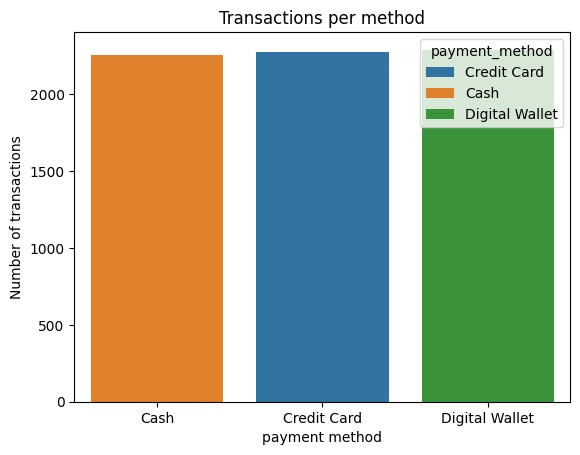

In [ ]:
sns.countplot(
    data=df_clean,
    x='payment_method',
    hue='payment_method',
    order=df_clean['payment_method'].value_counts().sort_values().index
)

plt.xlabel("payment method")
plt.ylabel("Number of transactions")
plt.title("Transactions per method")

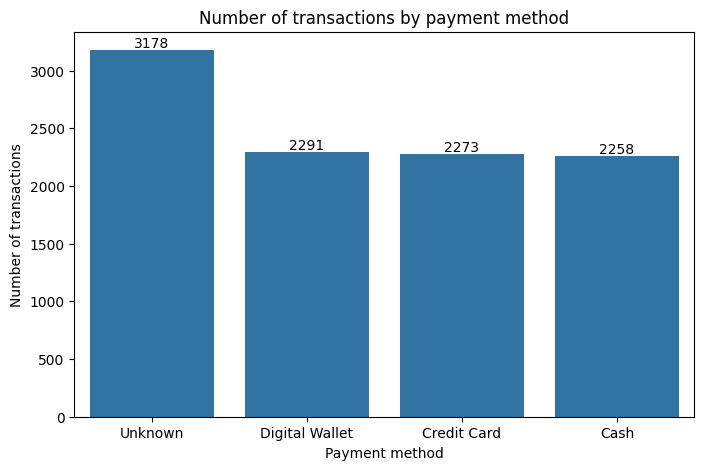

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    x=df_clean["payment_method"].fillna("Unknown"),
    order=df_clean["payment_method"]
        .fillna("Unknown")
        .value_counts()
        .index
)

ax.bar_label(ax.containers[0])

plt.xlabel("Payment method")
plt.ylabel("Number of transactions")
plt.title("Number of transactions by payment method")
plt.show()


In [ ]:
# Аналізуємо location
#1)найпопулярніш

In [ ]:
df_eda = df_clean.copy()

In [ ]:
df_eda['location'].fillna("Unknown", inplace=True)

/tmp/ipykernel_1316/3612745086.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_eda['location'].fillna("Unknown", inplace=True)


In [ ]:
df_eda['location'].value_counts()

,count
location,
Unknown,3961
Takeaway,3022
In-store,3017


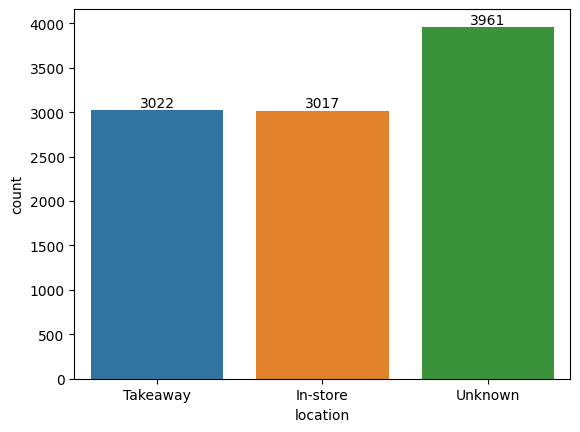

In [ ]:
ax = sns.countplot(
    data=df_eda,
    x="location",
    hue="location"
)

for c in ax.containers:
  ax.bar_label(c)

In [ ]:
revenue_by_location =(
    df_eda
    .groupby(by="location",as_index=False)["transaction_id"]
    .count()
)

In [ ]:
revenue_by_location

,location,transaction_id
0,In-store,3017
1,Takeaway,3022
2,Unknown,3961


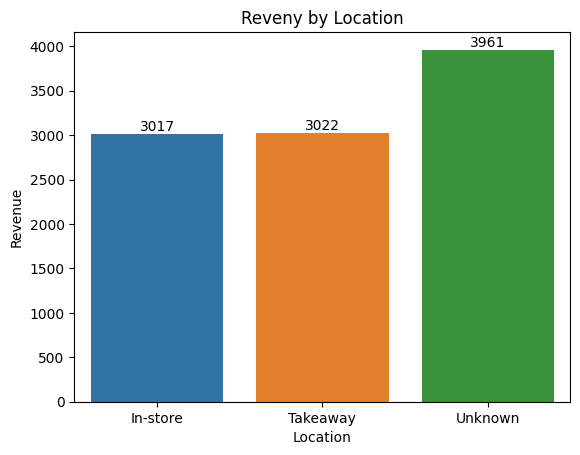

In [ ]:
ax = sns.barplot(
    data=revenue_by_location,
    x="location",
    y='transaction_id',
    hue="location"
)

for c in ax.containers:
  ax.bar_label(c)

plt.xlabel("Location")
plt.ylabel("Revenue")
plt.title("Reveny by Location")
plt.show()


In [ ]:
#тепер аналіз показників в залежності від часу

In [ ]:
df_eda['transaction_date'].dtype

dtype('<M8[ns]')

In [ ]:
df_eda['transaction_date'].max()

Timestamp('2023-12-31 00:00:00')

In [ ]:
df_eda['transaction_date'].min()

Timestamp('2023-01-01 00:00:00')

In [ ]:
df_eda['transaction_date'].isna().sum()

np.int64(460)

In [ ]:
# 1) виручку за місяцями;

In [ ]:
df_eda['day'] = pd.DatetimeIndex(data=df_eda['transaction_date']).day

In [ ]:
df_eda['month'] = pd.DatetimeIndex(data=df_eda['transaction_date']).month

In [ ]:
df_eda['year'] = pd.DatetimeIndex(data=df_eda['transaction_date']).year

In [ ]:
#####

In [ ]:
df_date = df_eda.copy()

In [ ]:
print(df_eda['transaction_date'].dtype)

datetime64[ns]


In [ ]:
df_date["transaction_date"] = pd.to_datetime(
    df_date["transaction_date"],
    errors="coerce"
)

In [ ]:
df_date = df_date.dropna(subset=['transaction_date'])

In [ ]:
#month

In [ ]:
df_date['month'] = (
    df_date['transaction_date']
    .dt.to_period("M")
    .dt.to_timestamp()
)
df_date["date"] = df_date["transaction_date"].dt.date
df_date["weekday"] = df_date["transaction_date"].dt.day_name()

In [ ]:
df_date

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,total_spent_calc,day,month,year,date,weekday
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,4.0,8.0,2023-09-01,2023.0,2023-09-08,Friday
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,12.0,16.0,2023-05-01,2023.0,2023-05-16,Tuesday
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,4.0,19.0,2023-07-01,2023.0,2023-07-19,Wednesday
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,Unknown,2023-04-27,10.0,27.0,2023-04-01,2023.0,2023-04-27,Thursday
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,4.0,11.0,2023-06-01,2023.0,2023-06-11,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,Unknown,2023-08-30,4.0,30.0,2023-08-01,2023.0,2023-08-30,Wednesday
9996,TXN_9659401,Cookie,3.0,1.0,3.0,Digital Wallet,Unknown,2023-06-02,NaN,2.0,2023-06-01,2023.0,2023-06-02,Friday
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,Unknown,2023-03-02,8.0,2.0,2023-03-01,2023.0,2023-03-02,Thursday
9998,TXN_7695629,Cookie,3.0,1.0,3.0,Digital Wallet,Unknown,2023-12-02,NaN,2.0,2023-12-01,2023.0,2023-12-02,Saturday


In [ ]:
# 1) i 2) Виручка і кількість транзакцій за місяцями

In [ ]:
monthly_sales = (
    df_date
    .groupby(by='month', as_index=False)
    .agg(
        total_revenue =("total_spent", "sum"),
        transaction_count = ("transaction_id", "nunique")
    )
)
monthly_sales

,month,total_revenue,transaction_count
0,2023-01-01,7254.0,818
1,2023-02-01,6644.0,727
2,2023-03-01,7216.0,827
3,2023-04-01,7179.0,774
4,2023-05-01,6957.5,777
5,2023-06-01,7353.0,818
6,2023-07-01,6877.5,791
7,2023-08-01,7112.5,803
8,2023-09-01,6871.0,788
9,2023-10-01,7314.0,838


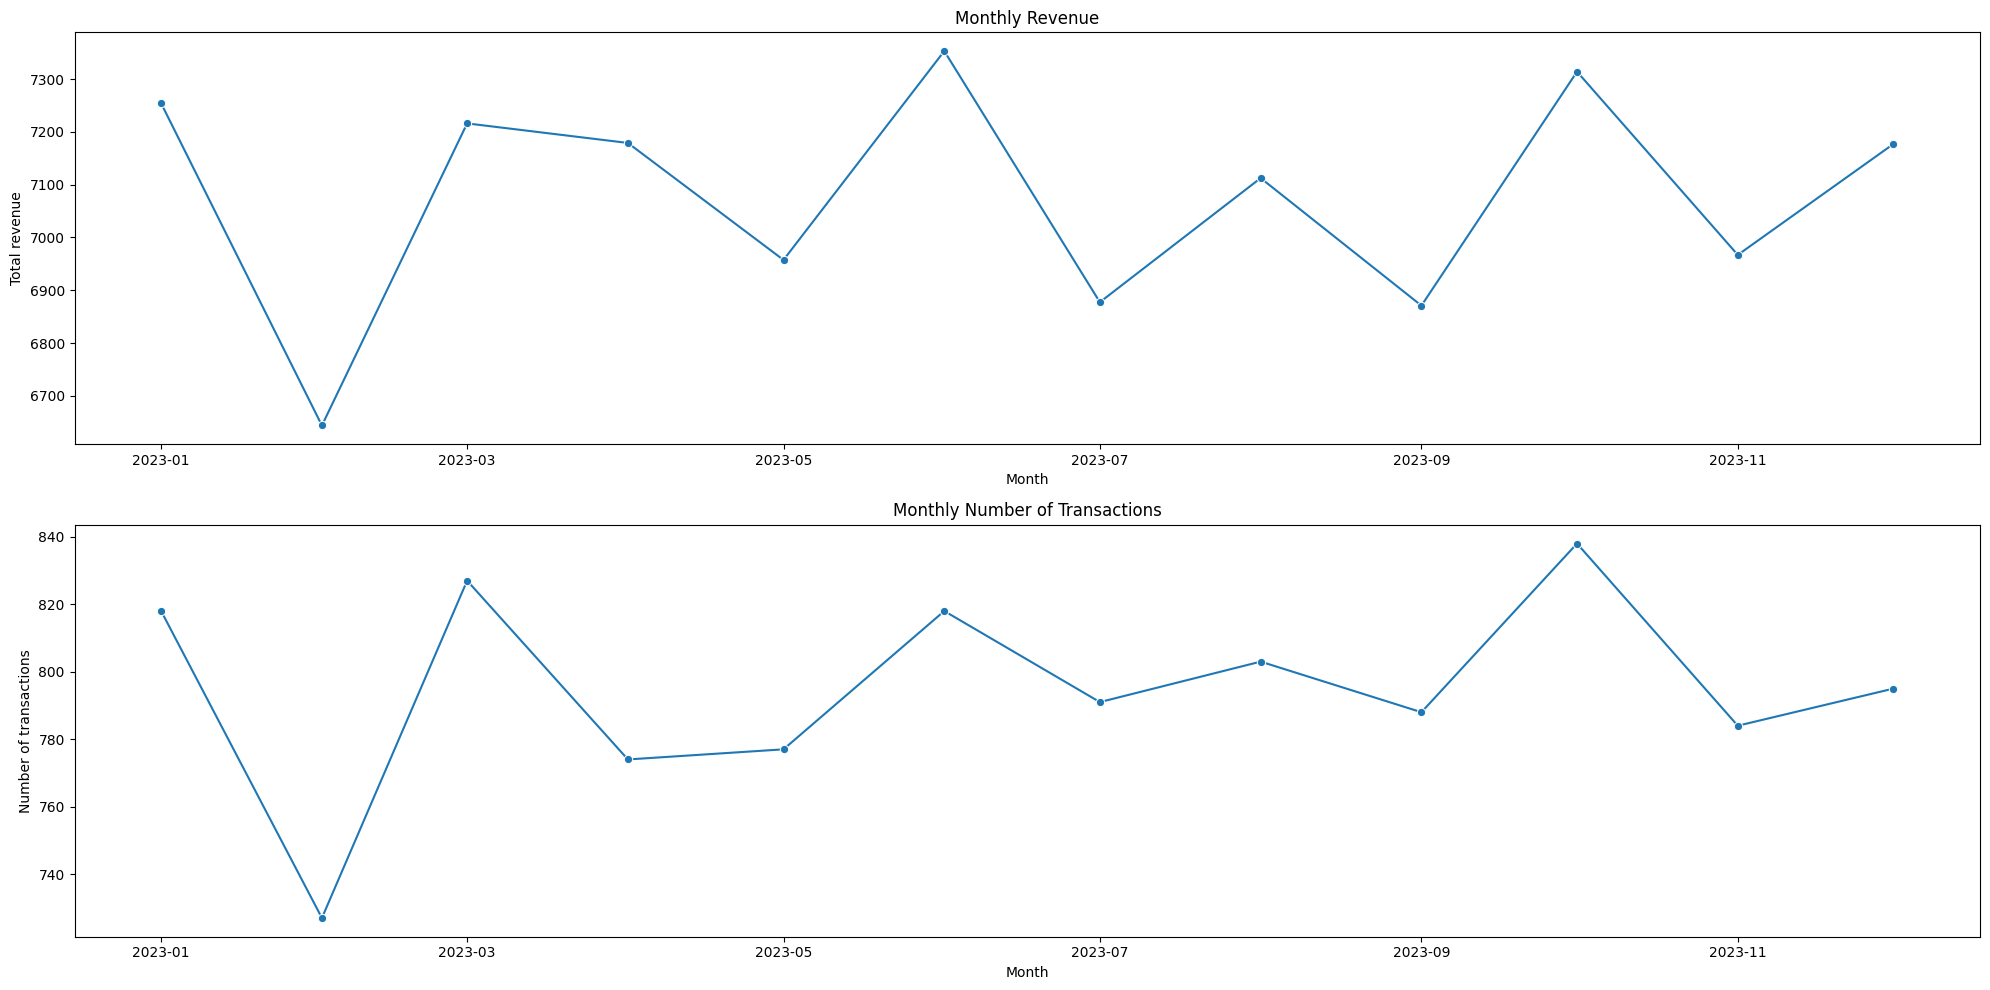

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(20, 10))
sns.lineplot(
    data=monthly_sales,
    x = "month",
    y='total_revenue',
    marker='o',
    ax=axes[0]
)
axes[0].set_title("Monthly Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Total revenue")

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="transaction_count",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Monthly Number of Transactions")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of transactions")

plt.tight_layout()
plt.show()

In [ ]:
#Найпопулярніші дні

In [ ]:
# 1) ORDER

In [ ]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

In [ ]:
weekday_revenue = (
    df_date
    .groupby(by='weekday')
    .agg(
        total_revenue = ('total_spent','sum'),
        transaction_count = ("transaction_id","nunique")
    ).reindex(index=weekday_order)
    .reset_index()
)

In [ ]:
weekday_revenue

,weekday,total_revenue,transaction_count
0,Monday,12140.0,1382
1,Tuesday,12039.5,1311
2,Wednesday,11680.5,1341
3,Thursday,12401.5,1380
4,Friday,12334.0,1388
5,Saturday,12039.5,1358
6,Sunday,12287.5,1380


<Axes: xlabel='weekday', ylabel='total_revenue'>

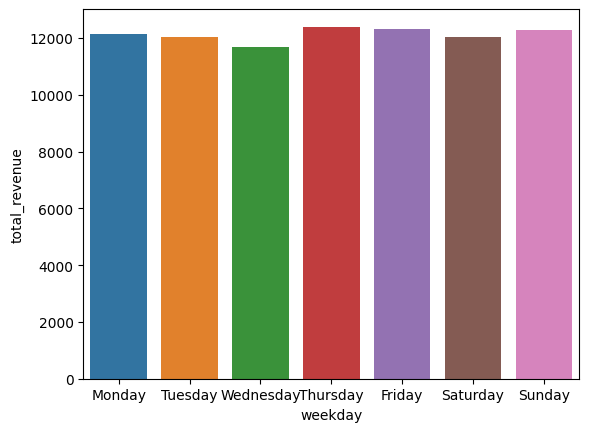

In [ ]:
sns.barplot(
    data=weekday_revenue,
    x="weekday",
    y="total_revenue",
    hue="weekday",
)

In [ ]:
#вивести топ 10 днів по продажу

In [ ]:
daily_sales = (
    df_date
    .groupby(by="transaction_date")
    .agg(
        total_revenue = ("total_spent","sum")
        , transaction_count = ("transaction_id", "nunique")
    )
).reset_index()

In [ ]:
daily_sales

,transaction_date,total_revenue,transaction_count
0,2023-01-01,176.0,20
1,2023-01-02,189.5,21
2,2023-01-03,194.0,21
3,2023-01-04,267.5,27
4,2023-01-05,363.5,38
...,...,...,...
360,2023-12-27,225.0,24
361,2023-12-28,175.0,21
362,2023-12-29,169.5,25
363,2023-12-30,210.0,27


In [ ]:
top_10_days =(
    daily_sales
    .nlargest(n=10,columns = "total_revenue")
    .sort_values("total_revenue")
)

In [ ]:
top_10_days['transaction_date'].dtype

dtype('<M8[ns]')

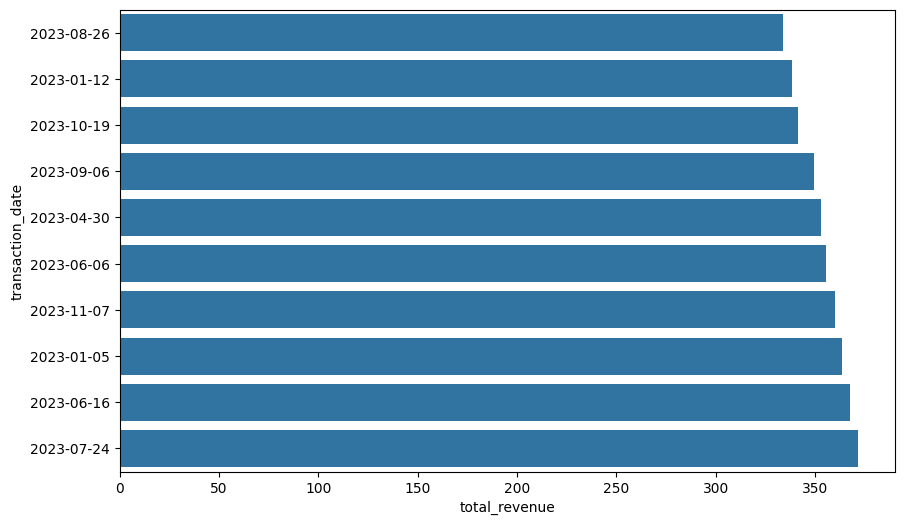

In [ ]:
top_10_days["transaction_date"] = top_10_days["transaction_date"].astype(str)
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_10_days,
    x="total_revenue",
    y="transaction_date"
)


In [ ]:
###

In [ ]:
total_revenue = df_eda["total_spent"].sum()
transaction_count = df_eda["transaction_id"].nunique()
total_items_sold = df_eda["quantity"].sum()

average_check = total_revenue / transaction_count
average_items_per_transaction = total_items_sold / transaction_count

print(f"Total revenue: ${total_revenue:,.2f}")
print(f"Number of transactions: {transaction_count:,}")
print(f"Items sold: {total_items_sold:,}")
print(f"Average check: ${average_check:.2f}")
print(f"Average items per transaction: {average_items_per_transaction:.2f}")

Total revenue: $89,096.00
Number of transactions: 10,000
Items sold: 30,180.0
Average check: $8.91
Average items per transaction: 3.02


In [ ]:
#

In [ ]:
analysis_df = df_eda.copy()

analysis_df["item"] = analysis_df["item"].fillna("Unknown")
analysis_df["payment_method"] = analysis_df["payment_method"].fillna("Unknown")
analysis_df["location"] = analysis_df["location"].fillna("Unknown")

In [ ]:
item_summary = (
    analysis_df
    .groupby("item", as_index=False)
    .agg(
        total_revenue=("total_spent", "sum"),
        items_sold=("quantity", "sum"),
        transaction_count=("transaction_id", "nunique")
    )
)

item_summary

,item,total_revenue,items_sold,transaction_count
0,Cake,10404.0,3468.0,1139
1,Coffee,7808.0,3904.0,1291
2,Cookie,3598.0,3598.0,1213
3,Juice,10515.0,3505.0,1171
4,Salad,19095.0,3819.0,1272
5,Sandwich,13716.0,3429.0,1131
6,Smoothie,13344.0,3336.0,1096
7,Tea,5475.0,3650.0,1207
8,Unknown,5141.0,1471.0,480


In [ ]:
item_summary = (
    analysis_df
    .groupby("item", as_index=False)
    .agg(
        total_revenue=("total_spent", "sum"),
        items_sold=("quantity", "sum"),
        transaction_count=("transaction_id", "nunique")
    )
)

item_summary

,item,total_revenue,items_sold,transaction_count
0,Cake,10404.0,3468.0,1139
1,Coffee,7808.0,3904.0,1291
2,Cookie,3598.0,3598.0,1213
3,Juice,10515.0,3505.0,1171
4,Salad,19095.0,3819.0,1272
5,Sandwich,13716.0,3429.0,1131
6,Smoothie,13344.0,3336.0,1096
7,Tea,5475.0,3650.0,1207
8,Unknown,5141.0,1471.0,480


In [ ]:
payment_summary = (
    analysis_df
    .groupby("payment_method", as_index=False)
    .agg(
        total_revenue=("total_spent", "sum"),
        transaction_count=("transaction_id", "nunique")
    )
)

payment_summary

,payment_method,total_revenue,transaction_count
0,Cash,20402.5,2258
1,Credit Card,20466.0,2273
2,Digital Wallet,20414.0,2291
3,Unknown,27813.5,3178


In [ ]:
location_summary = (
    analysis_df
    .groupby("location", as_index=False)
    .agg(
        total_revenue=("total_spent", "sum"),
        average_check=("total_spent", "mean"),
        transaction_count=("transaction_id", "nunique")
    )
)

location_summary

,location,total_revenue,average_check,transaction_count
0,In-store,27174.0,9.033910,3017
1,Takeaway,26552.5,8.803879,3022
2,Unknown,35369.5,8.947508,3961


In [ ]:
best_item_by_revenue = item_summary.loc[
    item_summary["total_revenue"].idxmax()
]

best_item_by_quantity = item_summary.loc[
    item_summary["items_sold"].idxmax()
]

best_payment_method = payment_summary.loc[
    payment_summary["transaction_count"].idxmax()
]

best_location = location_summary.loc[
    location_summary["total_revenue"].idxmax()
]

best_month = monthly_sales.loc[
    monthly_sales["total_revenue"].idxmax()
]


In [ ]:
print(
    "Top item by revenue:",
    best_item_by_revenue["item"],
    f"${best_item_by_revenue['total_revenue']:,.2f}"
)

print(
    "Top item by quantity:",
    best_item_by_quantity["item"],
    f"{best_item_by_quantity['items_sold']:,.0f} items"
)

print(
    "Most used payment method:",
    best_payment_method["payment_method"],
    f"{best_payment_method['transaction_count']:,.0f} transactions"
)

print(
    "Top location by revenue:",
    best_location["location"],
    f"${best_location['total_revenue']:,.2f}"
)

print(
    "Best month:",
    best_month["month"].strftime("%Y-%m"),
    f"${best_month['total_revenue']:,.2f}"
)



Top item by revenue: Salad $19,095.00
Top item by quantity: Coffee 3,904 items
Most used payment method: Unknown 3,178 transactions
Top location by revenue: Unknown $35,369.50
Best month: 2023-06 $7,353.00


In [ ]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_sales = (
    df_date
    .groupby("weekday")
    .agg(
        total_revenue=("total_spent", "sum"),
        transaction_count=("transaction_id", "nunique")
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_sales

,weekday,total_revenue,transaction_count
0,Monday,12140.0,1382
1,Tuesday,12039.5,1311
2,Wednesday,11680.5,1341
3,Thursday,12401.5,1380
4,Friday,12334.0,1388
5,Saturday,12039.5,1358
6,Sunday,12287.5,1380


In [ ]:
best_weekday = weekday_sales.loc[
    weekday_sales["total_revenue"].idxmax()
]

print(
    "Best weekday:",
    best_weekday["weekday"],
    f"${best_weekday['total_revenue']:,.2f}"
)

Best weekday: Thursday $12,401.50


In [ ]:
#Готуємо датасет для викорисання та побудови дашбордів у PowerBI
# Треба зберегти Csv

In [ ]:
df_dashboard = df_eda.copy()

In [ ]:
df_dashboard[["item","payment_method","location"]].fillna("Unknown", inplace=True)

/tmp/ipykernel_1316/786419616.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_dashboard[["item","payment_method","location"]].fillna("Unknown", inplace=True)


In [ ]:
df_dashboard['year'] = df_dashboard['year'].astype("Int64")

In [ ]:
df_dashboard['month_number'] = (
    df_dashboard['transaction_id'].dt.month.astype("Int64")
)

In [ ]:
df_dashboard['month'] = df_dashboard['month'].astype("Int64")

In [ ]:
df_dashboard['day'] = df_dashboard['day'].astype("Int64")

In [ ]:

df_dashboard["month_start"] = (
    df_dashboard["transaction_date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

In [ ]:
df_dashboard['month_name'] = (
    df_dashboard['transaction_date'].dt.month_name()
)

In [ ]:
df_dashboard['weekday'] = (
    df_dashboard['transaction_date']
    .dt.day_name()
)

In [ ]:
df_dashboard["weekday_number"] = (
    df_dashboard["transaction_date"]
    .dt.weekday
    .add(1)
    .astype("Int64")
)

In [ ]:
df_dashboard

,transaction_id,item,quantity,price_per_unit,total_spent,payment_method,location,transaction_date,total_spent_calc,day,month,year,month_start,month_name,weekday,weekday_number
0,TXN_1961373,Coffee,2.0,2.0,4.0,Credit Card,Takeaway,2023-09-08,4.0,8,9,2023,2023-09-01,September,Friday,5
1,TXN_4977031,Cake,4.0,3.0,12.0,Cash,In-store,2023-05-16,12.0,16,5,2023,2023-05-01,May,Tuesday,2
2,TXN_4271903,Cookie,4.0,1.0,4.0,Credit Card,In-store,2023-07-19,4.0,19,7,2023,2023-07-01,July,Wednesday,3
3,TXN_7034554,Salad,2.0,5.0,10.0,NaN,Unknown,2023-04-27,10.0,27,4,2023,2023-04-01,April,Thursday,4
4,TXN_3160411,Coffee,2.0,2.0,4.0,Digital Wallet,In-store,2023-06-11,4.0,11,6,2023,2023-06-01,June,Sunday,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2.0,2.0,4.0,NaN,Unknown,2023-08-30,4.0,30,8,2023,2023-08-01,August,Wednesday,3
9996,TXN_9659401,Cookie,3.0,1.0,3.0,Digital Wallet,Unknown,2023-06-02,NaN,2,6,2023,2023-06-01,June,Friday,5
9997,TXN_5255387,Coffee,4.0,2.0,8.0,Digital Wallet,Unknown,2023-03-02,8.0,2,3,2023,2023-03-01,March,Thursday,4
9998,TXN_7695629,Cookie,3.0,1.0,3.0,Digital Wallet,Unknown,2023-12-02,NaN,2,12,2023,2023-12-01,December,Saturday,6


In [ ]:
# Зберігаємо на Google Drive

In [ ]:
dashboard_path = (
    "/content/drive/MyDrive/"
    "CSV_files_for_DATA_cleaning/"
    "dirty_cafe_dashboard.csv"
)

In [ ]:
df_dashboard.to_csv(path_or_buf=dashboard_path)

In [ ]:
df_dashboard['payment_method'].isna().sum()

np.int64(3178)

In [ ]:
df_dashboard["item"] = df_dashboard["item"].fillna("Unknown")
df_dashboard["payment_method"] = df_dashboard["payment_method"].fillna("Unknown")
df_dashboard["location"] = df_dashboard["location"].fillna("Unknown")
df_dashboard["transaction_date"] = df_dashboard["transaction_date"].fillna("Unknown")